# Week 6 — Feature Engineering and Market Metrics

**Status:** Complete — technical workflow and analyst interpretation documented  
**Coverage:** January 2024 through September 2026  
**Primary dataset:** Sold Residential records  
**Confidentiality:** Aggregate outputs only; no MLS rows or identifiers are displayed.

This notebook records the analyst-approved business definitions, validates the implementation, and documents Bowen's interpretation of the aggregate results.

## 1. Metric register

| Metric | Formula | Valid records | Invalid treatment | Status |
|---|---|---|---|---|
| `close_to_original_list_ratio` | `ClosePrice / OriginalListPrice` | Both prices are present and greater than zero | Leave result missing | Approved and implemented |
| `close_price_per_sqft` | `ClosePrice / LivingArea` | Close price and living area are present and greater than zero | Leave result missing | Approved and implemented |
| `DaysOnMarket` | Existing raw field | Present and nonnegative; zero is valid | Preserve invalid records but exclude their values from summaries | Approved and validated |
| `close_year`, `close_month`, `year_month` | Derived from `CloseDate` | Valid parsed close date | Leave derived values missing | Approved and implemented; existing `year_month` reused as YrMo |
| `listing_to_contract_days` | `PurchaseContractDate - ListingContractDate` | Both dates present and nonnegative chronology | Leave result missing | Approved and implemented |
| `contract_to_close_days` | `CloseDate - PurchaseContractDate` | Both dates present and nonnegative chronology | Leave result missing | Approved and implemented |
| School district fields | Coordinate point-in-polygon match | Existing coordinate-quality flag is valid | Leave district fields missing | Approved and implemented with separate elementary, high, and unified name/code fields |

### Interpretation agreed before coding

For the close-to-original-list ratio:

- Below `1.0`: sold below original list price
- Exactly `1.0`: sold at original list price
- Above `1.0`: sold above original list price

The terms “undersold” and “oversold” are avoided because this ratio does not establish the property's true market value.

For PPSF, a higher value means the property sold for more per square foot of living area. It does **not** establish that safety, schools, groceries, or another neighborhood characteristic caused the difference. Location, property type, condition, age, amenities, and the mix of home sizes may all contribute.

The handbook lists “Price Ratio” and “Close to Original List Ratio” separately with the same formula. One column satisfies both definitions without creating a misleading duplicate.

For Days on Market, the handbook explicitly specifies the existing raw field. No duplicate column is created. Negative values are treated as invalid for summaries, while zero-day records remain valid.

For time-series analysis, `close_year` and `close_month` are created from `CloseDate`. The existing mortgage-enrichment field `year_month` already equals `YYYY-MM` from `CloseDate`, so it is validated and reused as the handbook's YrMo rather than duplicated.

`ListingContractDate` marks the start of the listing relationship; `PurchaseContractDate` marks an accepted buyer offer. Their nonnegative difference measures time from listing to contract. It does not reveal whether speed was caused by demand, pricing, condition, or another factor.

`contract_to_close_days` measures the full closing period after an offer is accepted. It can reflect financing, appraisal, inspection, title, escrow, and actions by both parties—not just the buyer.

The California 2024–25 source combines overlapping elementary, high-school, and unified boundaries. Separate name/code fields preserve every district type without duplicating property rows. Invalid coordinates, unmatched points, and same-type ambiguity remain measurable rather than being silently discarded.

## 2. Why the sold dataset is primary

Close-dependent metrics belong primarily in the sold dataset because it represents completed transactions. The listings dataset contains many records without `ClosePrice` or `CloseDate`; creating the same close-dependent columns there would produce mostly missing values without adding analytical meaning.

The Week 4–5 cleaned sold dataset remains unchanged. Week 6 writes a separate derived file: `data/processed/market_metrics_sold_residential.csv`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.week6_features import (
    CLOSE_MONTH_COLUMN,
    CONTRACT_TO_CLOSE_COLUMN,
    CONTRACT_TO_CLOSE_SPECIFICATION,
    CLOSE_YEAR_COLUMN,
    DOM_SPECIFICATION,
    LISTING_TO_CONTRACT_COLUMN,
    LISTING_TO_CONTRACT_SPECIFICATION,
    METRIC_SPECIFICATION,
    MIN_SEGMENT_RECORDS,
    OUTPUT_FILE,
    PPSF_COLUMN,
    PPSF_SPECIFICATION,
    RATIO_COLUMN,
    SCHOOL_DISTRICT_COLUMNS,
    SCHOOL_DISTRICT_SPECIFICATION,
    SEGMENT_OUTPUT_FILES,
    TIME_SPECIFICATION,
    process_sold_dataset,
)

## 3. Run and validate the approved metrics and enrichment

This cell reads the private Week 4–5 sold dataset, applies all metric eligibility rules, validates and derives the six metric groups, spatially matches coordinate-eligible properties to the California 2024–25 school-district boundaries, writes the separate Week 6 output, and independently reruns every saved validation—including the spatial join.

In [2]:
summary = process_sold_dataset()

Input: data/processed/analysis_ready_sold_residential.csv


CLOSE-TO-ORIGINAL-LIST RATIO
Formula: ClosePrice / OriginalListPrice
Total sold records: 495,334
Eligible records: 494,426 (99.82%)
Ineligible records: 908
Ineligibility reasons (categories can overlap):
  Missing ClosePrice: 2
  Nonpositive ClosePrice: 1
  Missing OriginalListPrice: 903
  Nonpositive OriginalListPrice: 2
Sale outcomes relative to original list price:
  Below: 254,515 (51.48%)
  At: 57,304 (11.59%)
  Above: 182,607 (36.93%)
Ratio distribution:
  Mean: 50.6149
  Median: 0.9944
  1st–99th percentile: 0.7467 to 1.2857
  Full range: 0.0000 to 9118000.0000

CLOSE PRICE PER SQUARE FOOT
Formula: ClosePrice / LivingArea
Eligible records: 494,880 (99.91%)
Ineligible records: 454
Ineligibility reasons (categories can overlap):
  Missing ClosePrice: 2
  Nonpositive ClosePrice: 1
  Missing LivingArea: 274
  Nonpositive LivingArea: 177
PPSF distribution:
  Mean: $641.13
  Median: $535.98
  1st–99th percentile: $160.13 to $1,896.63
  Full range: $0.00 to $1,164,066.85

DAYS ON MARKE

Saved-output validation passed.
Saved private segment table: data/processed/week6_segment_property_subtype.csv
Saved private segment table: data/processed/week6_segment_county.csv
Saved private segment table: data/processed/week6_segment_mls_area.csv


## 4. Metric eligibility, date coverage, school districts, and sale outcomes

Ineligibility categories can overlap. Zero-day values are retained as valid; negative durations remain preserved but excluded from their metrics. School-district results report aggregate match coverage only. Separate district-type columns preserve overlapping elementary, high, and unified service areas without duplicating MLS records.

In [3]:
metric_eligibility = pd.DataFrame(
    [
        {
            "metric": "Close-to-original-list ratio",
            "eligible_records": summary["eligible_records"],
            "eligible_share_percent": (
                summary["eligible_records"]
                / summary["total_records"]
                * 100
            ),
            "ineligible_records": summary["ineligible_records"],
        },
        {
            "metric": "Close price per square foot",
            "eligible_records": summary["ppsf_eligible_records"],
            "eligible_share_percent": (
                summary["ppsf_eligible_records"]
                / summary["total_records"]
                * 100
            ),
            "ineligible_records": summary["ppsf_ineligible_records"],
        },
        {
            "metric": "Days on Market",
            "eligible_records": summary["dom_eligible_records"],
            "eligible_share_percent": (
                summary["dom_eligible_records"]
                / summary["total_records"]
                * 100
            ),
            "ineligible_records": summary["dom_ineligible_records"],
        },
        {
            "metric": "Close-date time fields",
            "eligible_records": summary["time_eligible_records"],
            "eligible_share_percent": (
                summary["time_eligible_records"]
                / summary["total_records"]
                * 100
            ),
            "ineligible_records": summary["time_ineligible_records"],
        },
        {
            "metric": "Listing to contract days",
            "eligible_records": summary["ltc_eligible_records"],
            "eligible_share_percent": (
                summary["ltc_eligible_records"]
                / summary["total_records"]
                * 100
            ),
            "ineligible_records": summary["ltc_ineligible_records"],
        },
        {
            "metric": "Contract to close days",
            "eligible_records": summary["ctc_eligible_records"],
            "eligible_share_percent": (
                summary["ctc_eligible_records"]
                / summary["total_records"]
                * 100
            ),
            "ineligible_records": summary["ctc_ineligible_records"],
        },
    ]
)

ppsf_ineligibility = pd.DataFrame(
    [
        {
            "missing_close_price": summary["ppsf_missing_close_price"],
            "nonpositive_close_price": summary[
                "ppsf_nonpositive_close_price"
            ],
            "missing_living_area": summary["ppsf_missing_living_area"],
            "nonpositive_living_area": summary[
                "ppsf_nonpositive_living_area"
            ],
        }
    ]
)

outcome_keys = {
    "Below original list": "sold_below_original_list",
    "At original list": "sold_at_original_list",
    "Above original list": "sold_above_original_list",
}
outcomes = pd.DataFrame(
    [
        {
            "outcome": label,
            "records": summary[key],
            "share_of_eligible_percent": (
                summary[key] / summary["eligible_records"] * 100
            ),
        }
        for label, key in outcome_keys.items()
    ]
)

dom_quality = pd.DataFrame(
    [
        {
            "missing_days_on_market": summary["dom_missing_records"],
            "negative_days_on_market": summary["dom_negative_records"],
            "valid_zero_day_records": summary["dom_zero_records"],
        }
    ]
)

time_coverage = pd.DataFrame(
    [
        {
            "missing_close_date": summary["time_missing_close_date"],
            "close_date_parse_errors": summary["time_parse_errors"],
            "first_year_month": summary["time_first_year_month"],
            "last_year_month": summary["time_last_year_month"],
            "distinct_year_months": summary["time_distinct_year_months"],
        }
    ]
)

ltc_quality = pd.DataFrame(
    [
        {
            "missing_listing_date": summary["ltc_missing_listing_date"],
            "missing_purchase_date": summary["ltc_missing_purchase_date"],
            "negative_timeline": summary["ltc_negative_records"],
            "valid_zero_day_records": summary["ltc_zero_day_records"],
        }
    ]
)

ctc_quality = pd.DataFrame(
    [
        {
            "missing_purchase_date": summary["ctc_missing_purchase_date"],
            "missing_close_date": summary["ctc_missing_close_date"],
            "negative_timeline": summary["ctc_negative_records"],
            "valid_zero_day_records": summary["ctc_zero_day_records"],
        }
    ]
)

school_district_coverage = pd.DataFrame(
    [
        {
            "district_type": label,
            "unique_matches": summary[f"school_{key}_matched_records"],
            "ambiguous_matches": summary[
                f"school_{key}_ambiguous_records"
            ],
            "distinct_districts": summary[
                f"school_{key}_distinct_districts"
            ],
        }
        for label, key in (
            ("Elementary", "elementary"),
            ("High", "high"),
            ("Unified", "unified"),
        )
    ]
)

school_district_quality = pd.DataFrame(
    [
        {
            "total_records": summary["total_records"],
            "coordinate_eligible": summary[
                "school_coordinate_eligible_records"
            ],
            "invalid_coordinates": summary[
                "school_invalid_coordinate_records"
            ],
            "eligible_without_any_match": summary[
                "school_unmatched_eligible_records"
            ],
            "cross_type_overlap_preserved": summary[
                "school_cross_type_overlap_records"
            ],
            "source_geometries_repaired": summary[
                "school_invalid_geometry_before"
            ],
        }
    ]
)

display(metric_eligibility)
display(ppsf_ineligibility)
display(dom_quality)
display(time_coverage)
display(ltc_quality)
display(ctc_quality)
display(school_district_coverage)
display(school_district_quality)
display(outcomes)

,metric,eligible_records,eligible_share_percent,ineligible_records
0,Close-to-original-list ratio,494426,99.816689,908
1,Close price per square foot,494880,99.908345,454
2,Days on Market,495278,99.988694,56
3,Close-date time fields,495334,100.000000,0
4,Listing to contract days,494820,99.896232,514
5,Contract to close days,494894,99.911171,440


,missing_close_price,nonpositive_close_price,missing_living_area,nonpositive_living_area
0,2,1,274,177


,missing_days_on_market,negative_days_on_market,valid_zero_day_records
0,0,56,20011


,missing_close_date,close_date_parse_errors,first_year_month,last_year_month,distinct_year_months
0,0,0,2024-01,2026-09,33


,missing_listing_date,missing_purchase_date,negative_timeline,valid_zero_day_records
0,1,197,316,11169


,missing_purchase_date,missing_close_date,negative_timeline,valid_zero_day_records
0,197,0,243,8899


,district_type,unique_matches,ambiguous_matches,distinct_districts
0,Elementary,121334,0,422
1,High,118883,0,76
2,Unified,370946,0,333


,total_records,coordinate_eligible,invalid_coordinates,eligible_without_any_match,cross_type_overlap_preserved,source_geometries_repaired
0,495334,490422,4912,142,2000,7


,outcome,records,share_of_eligible_percent
0,Below original list,254515,51.476864
1,At original list,57304,11.590005
2,Above original list,182607,36.933131


## 5. Distribution review

All central charts are limited to their 1st–99th percentile ranges for readability. Full-range values remain in the output and are reported separately. Extreme-value treatment belongs to the handbook's Week 7 outlier phase, so no mathematically valid values are silently removed here.

,metric,mean,median,percentile_01,percentile_99,minimum,maximum
0,Close-to-original-list ratio,50.614876,0.994444,0.746686,1.285714,9.207366e-07,9.118000e+06
1,Close price per square foot,641.133574,535.982928,160.128102,1896.632181,4.981497e-04,1.164067e+06
2,Days on Market,37.651038,19.000000,0.000000,235.000000,0.000000e+00,1.243000e+04
3,Listing to contract days,45.646661,25.000000,0.000000,279.000000,0.000000e+00,1.465700e+04
4,Contract to close days,31.639854,29.000000,0.000000,117.000000,0.000000e+00,3.662900e+04


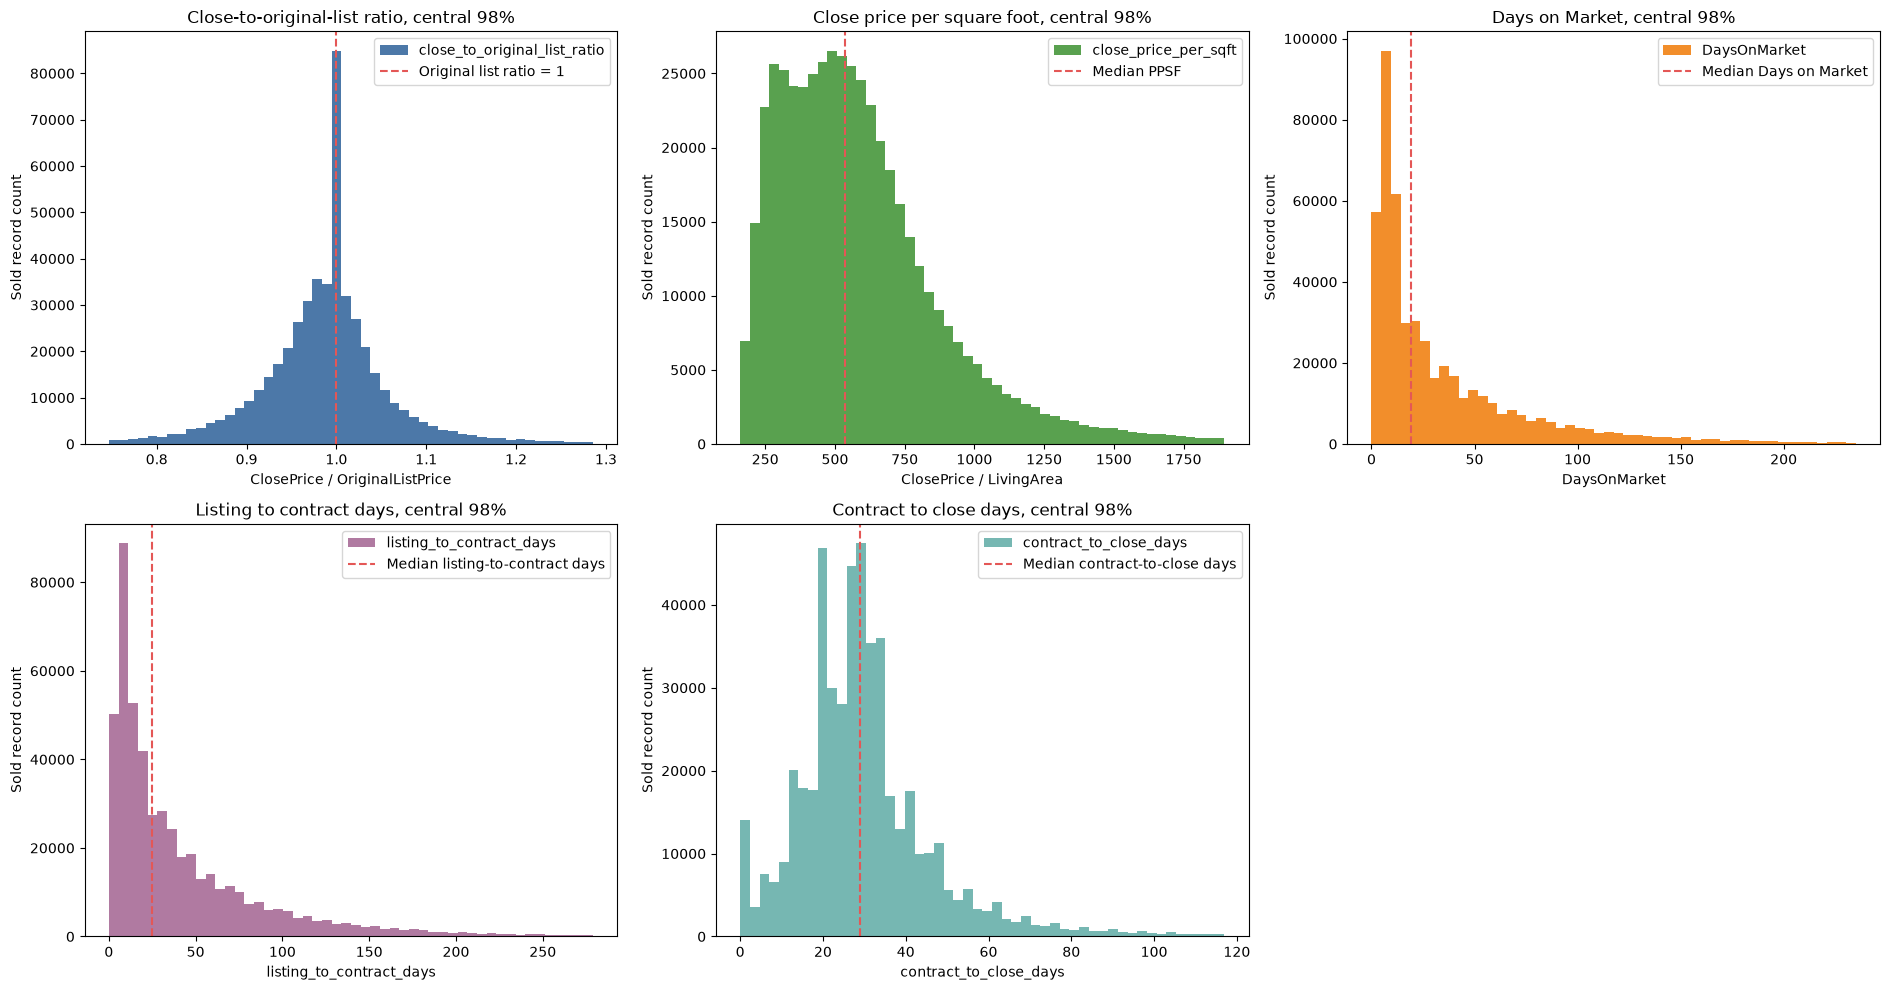

In [4]:
distribution = pd.DataFrame(
    [
        {
            "metric": "Close-to-original-list ratio",
            "mean": summary["ratio_mean"],
            "median": summary["ratio_median"],
            "percentile_01": summary["ratio_percentile_01"],
            "percentile_99": summary["ratio_percentile_99"],
            "minimum": summary["ratio_minimum"],
            "maximum": summary["ratio_maximum"],
        },
        {
            "metric": "Close price per square foot",
            "mean": summary["ppsf_mean"],
            "median": summary["ppsf_median"],
            "percentile_01": summary["ppsf_percentile_01"],
            "percentile_99": summary["ppsf_percentile_99"],
            "minimum": summary["ppsf_minimum"],
            "maximum": summary["ppsf_maximum"],
        },
        {
            "metric": "Days on Market",
            "mean": summary["dom_mean"],
            "median": summary["dom_median"],
            "percentile_01": summary["dom_percentile_01"],
            "percentile_99": summary["dom_percentile_99"],
            "minimum": summary["dom_minimum"],
            "maximum": summary["dom_maximum"],
        },
        {
            "metric": "Listing to contract days",
            "mean": summary["ltc_mean"],
            "median": summary["ltc_median"],
            "percentile_01": summary["ltc_percentile_01"],
            "percentile_99": summary["ltc_percentile_99"],
            "minimum": summary["ltc_minimum"],
            "maximum": summary["ltc_maximum"],
        },
        {
            "metric": "Contract to close days",
            "mean": summary["ctc_mean"],
            "median": summary["ctc_median"],
            "percentile_01": summary["ctc_percentile_01"],
            "percentile_99": summary["ctc_percentile_99"],
            "minimum": summary["ctc_minimum"],
            "maximum": summary["ctc_maximum"],
        },
    ]
)
display(distribution)

metrics = pd.read_csv(
    OUTPUT_FILE,
    usecols=[
        RATIO_COLUMN,
        PPSF_COLUMN,
        "DaysOnMarket",
        LISTING_TO_CONTRACT_COLUMN,
        CONTRACT_TO_CLOSE_COLUMN,
    ],
)
ratio_central = metrics[RATIO_COLUMN].loc[
    metrics[RATIO_COLUMN].between(
        summary["ratio_percentile_01"],
        summary["ratio_percentile_99"],
    )
]
ppsf_central = metrics[PPSF_COLUMN].loc[
    metrics[PPSF_COLUMN].between(
        summary["ppsf_percentile_01"],
        summary["ppsf_percentile_99"],
    )
]
dom_central = metrics["DaysOnMarket"].loc[
    metrics["DaysOnMarket"].between(
        summary["dom_percentile_01"],
        summary["dom_percentile_99"],
    )
]
ltc_central = metrics[LISTING_TO_CONTRACT_COLUMN].loc[
    metrics[LISTING_TO_CONTRACT_COLUMN].between(
        summary["ltc_percentile_01"],
        summary["ltc_percentile_99"],
    )
]
ctc_central = metrics[CONTRACT_TO_CLOSE_COLUMN].loc[
    metrics[CONTRACT_TO_CLOSE_COLUMN].between(
        summary["ctc_percentile_01"],
        summary["ctc_percentile_99"],
    )
]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
axes = axes.ravel()
ratio_central.plot.hist(bins=50, color="#4C78A8", ax=axes[0])
axes[0].axvline(
    1.0,
    color="#E45756",
    linestyle="--",
    label="Original list ratio = 1",
)
axes[0].set_title("Close-to-original-list ratio, central 98%")
axes[0].set_xlabel("ClosePrice / OriginalListPrice")
axes[0].set_ylabel("Sold record count")
axes[0].legend()

ppsf_central.plot.hist(bins=50, color="#59A14F", ax=axes[1])
axes[1].axvline(
    summary["ppsf_median"],
    color="#E45756",
    linestyle="--",
    label="Median PPSF",
)
axes[1].set_title("Close price per square foot, central 98%")
axes[1].set_xlabel("ClosePrice / LivingArea")
axes[1].set_ylabel("Sold record count")
axes[1].legend()

dom_central.plot.hist(bins=50, color="#F28E2B", ax=axes[2])
axes[2].axvline(
    summary["dom_median"],
    color="#E45756",
    linestyle="--",
    label="Median Days on Market",
)
axes[2].set_title("Days on Market, central 98%")
axes[2].set_xlabel("DaysOnMarket")
axes[2].set_ylabel("Sold record count")
axes[2].legend()

ltc_central.plot.hist(bins=50, color="#B07AA1", ax=axes[3])
axes[3].axvline(
    summary["ltc_median"],
    color="#E45756",
    linestyle="--",
    label="Median listing-to-contract days",
)
axes[3].set_title("Listing to contract days, central 98%")
axes[3].set_xlabel(LISTING_TO_CONTRACT_COLUMN)
axes[3].set_ylabel("Sold record count")
axes[3].legend()

ctc_central.plot.hist(bins=50, color="#76B7B2", ax=axes[4])
axes[4].axvline(
    summary["ctc_median"],
    color="#E45756",
    linestyle="--",
    label="Median contract-to-close days",
)
axes[4].set_title("Contract to close days, central 98%")
axes[4].set_xlabel(CONTRACT_TO_CLOSE_COLUMN)
axes[4].set_ylabel("Sold record count")
axes[4].legend()
axes[5].axis("off")

plt.tight_layout()
plt.show()

## 6. Safe sample of the engineered columns

The handbook asks for a sample output table showing the engineered fields populated correctly. To prevent private row-level MLS data from entering Git, this example uses two clearly synthetic transactions and applies the documented formulas. The production results are validated separately above.


In [5]:
synthetic_sample = pd.DataFrame(
    {
        "ClosePrice": [500_000, 525_000],
        "OriginalListPrice": [520_000, 500_000],
        "LivingArea": [1_250, 1_500],
        "DaysOnMarket": [18, 9],
        "ListingContractDate": ["2026-04-20", "2026-06-01"],
        "PurchaseContractDate": ["2026-05-10", "2026-06-08"],
        "CloseDate": ["2026-06-10", "2026-07-02"],
    },
    index=["Synthetic A", "Synthetic B"],
)

for date_column in (
    "ListingContractDate",
    "PurchaseContractDate",
    "CloseDate",
):
    synthetic_sample[date_column] = pd.to_datetime(
        synthetic_sample[date_column]
    )

synthetic_sample[RATIO_COLUMN] = (
    synthetic_sample["ClosePrice"]
    / synthetic_sample["OriginalListPrice"]
)
synthetic_sample[PPSF_COLUMN] = (
    synthetic_sample["ClosePrice"] / synthetic_sample["LivingArea"]
)
synthetic_sample[CLOSE_YEAR_COLUMN] = (
    synthetic_sample["CloseDate"].dt.year
)
synthetic_sample[CLOSE_MONTH_COLUMN] = (
    synthetic_sample["CloseDate"].dt.month
)
synthetic_sample["year_month"] = (
    synthetic_sample["CloseDate"].dt.strftime("%Y-%m")
)
synthetic_sample[LISTING_TO_CONTRACT_COLUMN] = (
    synthetic_sample["PurchaseContractDate"]
    - synthetic_sample["ListingContractDate"]
).dt.days
synthetic_sample[CONTRACT_TO_CLOSE_COLUMN] = (
    synthetic_sample["CloseDate"]
    - synthetic_sample["PurchaseContractDate"]
).dt.days

display(
    synthetic_sample[
        [
            RATIO_COLUMN,
            PPSF_COLUMN,
            "DaysOnMarket",
            CLOSE_YEAR_COLUMN,
            CLOSE_MONTH_COLUMN,
            "year_month",
            LISTING_TO_CONTRACT_COLUMN,
            CONTRACT_TO_CLOSE_COLUMN,
        ]
    ].round(4)
)


,close_to_original_list_ratio,close_price_per_sqft,DaysOnMarket,close_year,close_month,year_month,listing_to_contract_days,contract_to_close_days
Synthetic A,0.9615,400.0,18,2026,6,2026-06,20,31
Synthetic B,1.0500,350.0,9,2026,7,2026-07,7,24


## 7. Segmented market comparison

The three analyst-selected dimensions are compared using the same statistics: record count and share, median close price, median PPSF, median close-to-original-list ratio, median Days on Market, median listing-to-contract days, and median contract-to-close days.

Only groups with at least 100 sold records are retained. This minimum reduces unstable results from very small samples; it does not make unlike properties directly comparable or establish causation. The MLS-area presentation excludes the label “Not Defined,” while its volume remains reported in the coverage table.


In [6]:
segment_coverage = pd.DataFrame(
    [
        {
            "segment": label,
            "distinct_values": summary[
                f"segment_{slug}_distinct_values"
            ],
            "missing_records": summary[
                f"segment_{slug}_missing_records"
            ],
            "not_defined_records": summary[
                f"segment_{slug}_not_defined_records"
            ],
            "groups_with_at_least_100_records": summary[
                f"segment_{slug}_qualifying_groups"
            ],
        }
        for label, slug in (
            ("PropertySubType", "property_subtype"),
            ("CountyOrParish", "county"),
            ("MLSAreaMajor", "mls_area"),
        )
    ]
)
display(segment_coverage)

segment_columns = [
    "segment",
    "records",
    "share_of_all_records_percent",
    "median_close_price",
    "median_close_price_per_sqft",
    "median_close_to_original_ratio",
    "median_days_on_market",
    "median_listing_to_contract_days",
    "median_contract_to_close_days",
]

segment_tables = {
    field: pd.read_csv(path).sort_values(
        "records",
        ascending=False,
    )
    for field, path in SEGMENT_OUTPUT_FILES.items()
}

property_subtypes = segment_tables["PropertySubType"]
counties = segment_tables["CountyOrParish"].head(15)
defined_mls_areas = segment_tables["MLSAreaMajor"].loc[
    ~segment_tables["MLSAreaMajor"]["segment"].str.contains(
        "not defined",
        case=False,
        na=False,
    )
].head(15)

print(
    f"PropertySubType groups with at least "
    f"{MIN_SEGMENT_RECORDS:,} records"
)
display(property_subtypes[segment_columns].round(4))

print("15 largest CountyOrParish groups")
display(counties[segment_columns].round(4))

print("15 largest defined MLSAreaMajor groups")
display(defined_mls_areas[segment_columns].round(4))


,segment,distinct_values,missing_records,not_defined_records,groups_with_at_least_100_records
0,PropertySubType,20,923,0,11
1,CountyOrParish,63,0,0,44
2,MLSAreaMajor,1097,67273,50310,598


PropertySubType groups with at least 100 records


,segment,records,share_of_all_records_percent,median_close_price,median_close_price_per_sqft,median_close_to_original_ratio,median_days_on_market,median_listing_to_contract_days,median_contract_to_close_days
0,SingleFamilyResidence,371242,74.9478,897000.0,532.5815,1.0000,17.0,24.0,29.0
1,Condominium,81160,16.3849,625000.0,561.7198,0.9848,25.0,30.0,28.0
2,Townhouse,29035,5.8617,800000.0,557.7667,1.0000,18.0,23.0,28.0
3,ManufacturedOnLand,6401,1.2923,321500.0,225.5682,0.9702,30.0,39.0,33.0
4,Duplex,2779,0.5610,910000.0,543.4783,0.9829,22.0,31.0,32.0
5,StockCooperative,1940,0.3917,362750.0,396.9848,0.9834,21.0,32.0,46.0
6,Cabin,584,0.1179,250000.0,297.8826,0.9220,46.0,55.5,30.0
7,Triplex,422,0.0852,1125000.0,466.9747,0.9669,30.0,45.5,35.0
8,MixedUse,246,0.0497,657500.0,430.0000,0.9334,53.0,67.0,32.0
9,Quadruplex,185,0.0373,1250500.0,374.3162,0.9500,32.0,42.0,36.0


15 largest CountyOrParish groups


,segment,records,share_of_all_records_percent,median_close_price,median_close_price_per_sqft,median_close_to_original_ratio,median_days_on_market,median_listing_to_contract_days,median_contract_to_close_days
0,Los Angeles,123100,24.8519,905000.0,608.5985,0.9988,19.0,26.0,30.0
1,Riverside,68322,13.7931,600000.0,320.6997,0.9854,30.0,38.0,30.0
2,San Diego,61665,12.4492,900000.0,589.8685,0.9917,15.0,22.0,26.0
3,Orange,55787,11.2625,1185000.0,674.9936,0.9929,15.0,26.0,29.0
4,San Bernardino,46087,9.3042,535000.0,332.0027,0.9920,25.0,32.0,32.0
5,Alameda,23436,4.7314,1130000.0,698.8756,1.0186,14.0,14.0,23.0
6,Contra Costa,22741,4.5910,825000.0,520.2475,1.0000,14.0,15.0,23.0
7,Santa Clara,21069,4.2535,1590000.0,961.5385,1.0193,10.0,10.0,24.0
8,Ventura,15592,3.1478,870000.0,515.8730,0.9894,28.0,35.0,24.0
9,San Mateo,8457,1.7073,1700000.0,1051.8868,1.0127,12.0,12.0,23.0


15 largest defined MLSAreaMajor groups


,segment,records,share_of_all_records_percent,median_close_price,median_close_price_per_sqft,median_close_to_original_ratio,median_days_on_market,median_listing_to_contract_days,median_contract_to_close_days
1,SRCAR - Southwest Riverside County,24163,4.8781,589000.0,294.1176,0.9957,24.0,33.0,31.0
2,252 - Riverside,6275,1.2668,660000.0,378.5714,1.0000,20.0,28.0,31.0
3,248 - Corona,3987,0.8049,757500.0,396.3795,0.9941,22.0,31.0,31.0
4,LAC - Lancaster,3653,0.7375,475000.0,270.5882,1.0000,25.0,30.0,34.0
5,VIC - Victorville,3527,0.7120,439900.0,238.1232,1.0000,25.0,32.0,34.0
6,263 - Banning/Beaumont/Cherry Valley,3487,0.7040,499000.0,260.0104,0.9922,30.0,37.0,34.0
7,274 - San Bernardino,3430,0.6925,500000.0,353.9962,1.0000,20.0,28.0,33.0
8,259 - Moreno Valley,3177,0.6414,555000.0,312.4442,1.0000,18.0,27.0,33.0
9,686 - Ontario,3125,0.6309,653931.0,415.1527,1.0000,20.0,26.0,32.0
10,264 - Fontana,3047,0.6151,649704.0,359.4611,1.0000,18.0,26.0,32.0


## 8. Analyst interpretation — Bowen's documented findings

### Metric 1: Close-to-original-list ratio

Among eligible Residential sold records, the median ratio was `0.9944`. The typical property therefore closed at 99.44% of its original list price, approximately 0.56% below the original asking price. This does not mean most prices were unchanged: only 11.59% closed exactly at original list price.

### Metric 2: Close price per square foot

Among eligible Residential sold records, the median PPSF was `$535.98`. This means the typical eligible property sold for approximately `$536` per square foot of living area. PPSF alone does not establish affordability or explain why one area is more expensive; total price, size, financing, geography, property mix, and other factors matter.

### Metric 3: Days on Market

Among eligible Residential sold records, the median Days on Market was `19` days. This means half of eligible properties recorded 19 days or less and half recorded 19 days or more. The 37.65-day mean is much higher, so the distribution's long right tail still needs interpretation and Week 7 outlier review.

### Metric 4: Close-date time fields

`close_month` alone would combine the same calendar month across different years even though market behavior can change from year to year. `year_month` keeps January 2024, January 2025, and January 2026 separate, preserves chronological order, and supports monthly trend analysis. All sold records have valid time fields covering 33 months from January 2024 through September 2026.

### Metric 5: Listing to contract days

`ListingContractDate` is when the property is listed under the brokerage agreement; `PurchaseContractDate` is when a buyer's offer is accepted. The median valid difference is `25` days. Shorter periods may be associated with strong demand or attractive pricing, but this metric alone cannot establish the cause.

The 25-day median means half of eligible properties reached an accepted purchase contract within 25 days of listing and half took 25 days or longer. The 45.65-day mean is much higher than the median, indicating a long right tail. The 14,657-day maximum remains preserved for formal Week 7 outlier review.

### Metric 6: Contract to close days

This metric measures how long the complete closing process takes after an accepted purchase contract. It can involve financing, appraisal, inspection, title, escrow, and responsibilities of both parties. The median valid period is `29` days.

The 29-day median means half of eligible transactions closed within 29 days after the accepted purchase contract and half took 29 days or longer. The 36,629-day maximum remains preserved for formal Week 7 outlier review before this metric is averaged across market segments.

### School-district enrichment

The 2024–25 district boundary file contains elementary, high-school, and unified service areas. Separate columns preserve overlapping district types. Of 490,422 coordinate-eligible sold records, only 142 did not match any district. No point had multiple matches within the same district type; 2,000 cross-type overlaps were preserved in their separate fields. The 4,912 records already flagged for invalid coordinates remain in the table with missing district values.

This is a geographic assignment based on reported coordinates and 2024–25 boundaries. It does not establish school quality, attendance eligibility at a particular school, or causal effects on price.

### Segmented analysis

#### PropertySubType

Among single-family residences, condominiums, and townhouses, condominiums had the lowest median sale price at `$625,000` but the highest median PPSF at `$561.72`. One possible explanation is that condominiums tend to have smaller living areas, although location, amenities, and property mix could also contribute. Condominiums took the longest to sell, with a median of `25` Days on Market. Their median close-to-original-list ratio of `0.9848` means the typical eligible condominium sold for 98.48% of its original asking price, approximately 1.52% below it.

PPSF is calculated for each property as `ClosePrice / LivingArea` and then summarized with the median. It is not calculated by dividing the segment's total price by its total square footage.

#### CountyOrParish

Among the five largest county groups, Orange County had the highest median sale price at `$1,185,000` and the highest median PPSF at `$674.99`. San Bernardino had the lowest median price at `$535,000`, while Riverside had the lowest median PPSF at `$320.70`. Riverside also had the longest median Days on Market at `30` days.

Compared with Orange County, Riverside's median price was `$585,000`, or 49.37%, lower, and its median PPSF was `$354.29`, or 52.49%, lower. Riverside's median selling time was 30 days, twice Orange County's 15 days. Riverside's close-to-original-list ratio of `0.9854` means the typical eligible property closed at 98.54% of its original asking price—approximately 1.46% below it. Orange County's ratio of `0.9929` indicates a smaller typical discount of approximately 0.71%.

Riverside contains 12,535 more records than Orange County in this dataset, or 22.47% more relative to Orange County. This describes dataset coverage and does not establish the total size of either county's housing market. Higher prices and PPSF also do not establish that residents of one county are wealthier; resident income and wealth are outside this dataset.

#### MLSAreaMajor

Among the five largest defined MLS areas, Corona had the highest median sale price at `$757,500` and highest median PPSF at `$396.38`. Victorville had the lowest median price at `$439,900` and lowest median PPSF at `$238.12`. Riverside had the shortest median Days on Market at `20` days.

Compared with Victorville, Corona had 460 more records, a `$317,600` higher median price, and a `$158.26` higher median PPSF. Corona's median selling time was also three days shorter. Corona's ratio of `0.9941` means its typical eligible property closed at approximately 99.41% of its original asking price, or 0.59% below it. Victorville's median ratio of `1.0000` means the middle ratio was at the original asking price; it does not mean every Victorville property sold at that price. Missing or ineligible ratios remain missing and are excluded from the median rather than being converted to zero.

`MLSAreaMajor` is more granular and fragmented than county. It contains 1,097 distinct labels, 67,273 missing records, and 50,310 records labeled `Not Defined`. Furthermore, the largest defined MLS area represents only 4.88% of the complete dataset. Individual MLS areas are therefore not representative of the statewide market. County is more appropriate for the initial comparison, while MLS area is better suited to a detailed local drill-down.

These segment findings are descriptive. They identify patterns in this dataset but do not prove that property type or location caused the differences.


## 9. Current deliverables and remaining Week 6 work

Created and validated:

- `src/week6_features.py` — reusable formulas, validity rules, audits, time derivations, duration calculations, school-district spatial matching, three segmented summaries, and independent saved-output validation
- `data/processed/market_metrics_sold_residential.csv` — private derived sold dataset with all 495,334 rows and 97 columns: 85 input columns, six new metric columns, and six school-district fields
- Three private segment CSVs — `PropertySubType`, `CountyOrParish`, and `MLSAreaMajor`, restricted to groups with at least 100 records
- This notebook — specifications, validations, aggregate results, a safe synthetic sample-output table, segment comparisons, Bowen's documented interpretations, district coverage, and data-quality boundaries
- `reports/week6_market_metrics_report.md` — supervisor-facing final report with handbook completion evidence, findings, limitations, and Week 7 handoff

All Week 6 deliverable requirements, analyst interpretations, and the final written report are complete. The project is ready to begin Week 7 outlier detection.
